In [2]:
import sklearn
import scipy as sp
import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder

import matplotlib.pyplot as plt
from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler, MinMaxScaler

#Exercise 1: Load the Titanic dataset and check for duplicates

#import file
# Read the Titanic CSV file into a pandas DataFrame
df = pd.read_csv("train.csv")


# Count the number of duplicate rows across all columns
num_duplicates = df.duplicated().sum()

print(f"Number of duplicates before removal: {num_duplicates}")

# Display any duplicate rows
duplicate_rows = df[df.duplicated(keep=False)]

print("\nDuplicate rows:")
print(duplicate_rows)

# Remove duplicate rows
df_clean = df.drop_duplicates()

# Verify that duplicates have been removed
remaining_duplicates = df_clean.duplicated().sum()

print(f"\nNumber of duplicates after removal: {remaining_duplicates}")

# Compare row counts before and after
print(f"\nOriginal number of rows: {len(df)}")
print(f"Number of rows after removing duplicates: {len(df_clean)}")


FileNotFoundError: [Errno 2] No such file or directory: 'train.csv'

In [ ]:
#Exercise 2: Check for missing values in the Titanic dataset
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values)

# Display only columns that contain missing values
print("\nColumns with missing values:")
print(missing_values[missing_values > 0])

# Remove rows with missing values
df = df.dropna()

# Create a copy so the original dataset remains unchanged
df_dropna = df.copy()

# Remove rows containing ANY missing values
df_dropna = df_dropna.dropna()

print(
    f"\nNumber of rows after dropna(): {len(df_dropna)}"
)

# Create another copy
df_fillna = df.copy()

# Replace missing Cabin values with a constant string
df_fillna["Cabin"] = df_fillna["Cabin"].fillna("Unknown")

# Replace missing Embarked values with a constant value
df_fillna["Embarked"] = df_fillna["Embarked"].fillna("Missing")

print("\nMissing values after fillna():")
print(df_fillna[["Cabin", "Embarked"]].isnull().sum())

# Note:
# This approach is useful for categorical columns where
# "Unknown" or "Missing" is meaningful.

# Create another copy
df_imputed = df.copy()
from sklearn.impute import SimpleImputer

# Create an imputer that replaces missing values
# with the median of the column
age_imputer = SimpleImputer(strategy="median")

# Fit the imputer and replace missing Age values
df_imputed["Age"] = age_imputer.fit_transform(
    df_imputed[["Age"]]
)

print("\nMissing Age values after imputation:")
print(df_imputed["Age"].isnull().sum())

# Median is often preferred for Age because it is less affected by extreme values than the mean.

# Create a final cleaned dataset
df_clean = df.copy()

# Fill missing Cabin values with a constant
df_clean["Cabin"] = df_clean["Cabin"].fillna("Unknown")

# Impute Age with the median value
age_imputer = SimpleImputer(strategy="median")
df_clean["Age"] = age_imputer.fit_transform(
    df_clean[["Age"]]
)

# Remove rows where Embarked is missing
df_clean = df_clean.dropna(subset=["Embarked"])

print("\nRemaining missing values in cleaned dataset:")
print(df_clean.isnull().sum())

print(f"\nNumber of rows in cleaned dataset: {len(df_clean)}")


1. New York City: $62,037
2. Los Angeles: $30,441
3. Seattle: $29,156
4. San Francisco: $17,507
5. Detroit: $13,182
6. Lafayette: $10,018
7. Jackson: $7,582
8. Atlanta: $6,994
9. Minneapolis: $6,825
10. San Diego: $6,377
11. Springfield: $6,201
12. Columbus: $5,897
13. Newark: $5,794
14. Columbia: $5,606
15. Richmond: $5,567
16. Providence: $5,506
17. Henderson: $4,912
18. Arlington: $4,170
19. Lakewood: $3,234
20. Milwaukee: $2,793


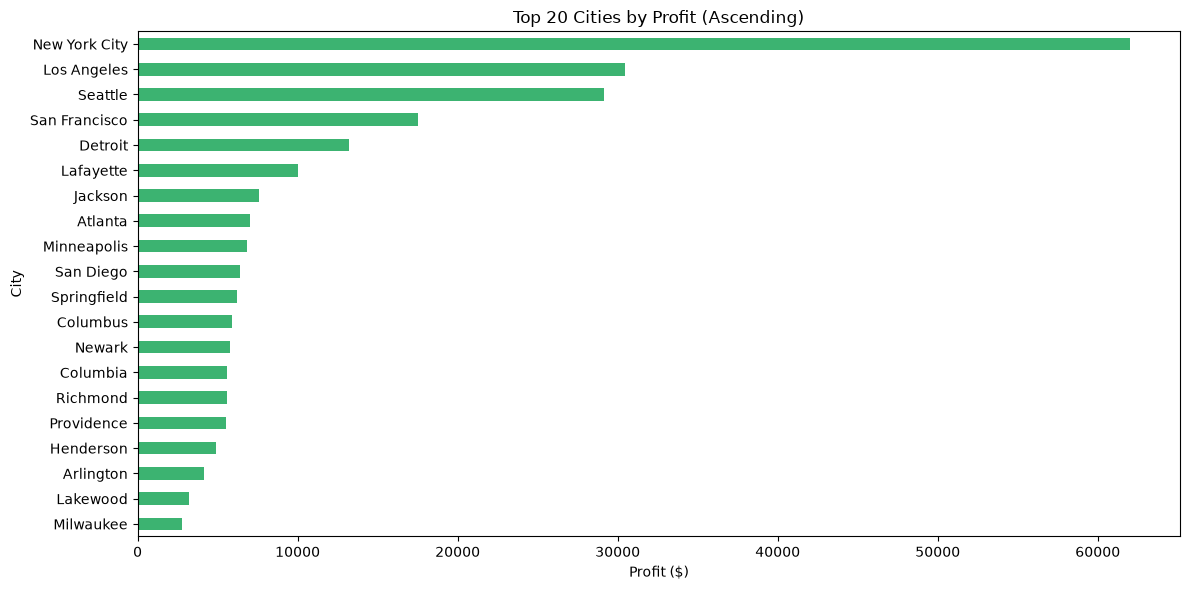

In [ ]:
import matplotlib.pyplot as plt

# Top 20 cities by profit

# Group the data by city, calculate total profit for each city,
# sort from highest profit to lowest, and keep only the top 20 cities
top_20_cities_profit = (
    df.groupby("City")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

# Print a ranked list of the top 20 cities and their total profits
# enumerate() adds ranking numbers starting at 1
for i, (city, profit) in enumerate(top_20_cities_profit.items(), start=1):
    print(f"{i}. {city}: ${profit:,.0f}")

plt.figure(figsize=(12, 6))

top_20_cities.plot(
    kind="barh",  # horizontal bars work well for rankings
    color="mediumseagreen"
)

plt.title("Top 20 Cities by Profit (Ascending)")
plt.xlabel("Profit ($)")
plt.ylabel("City")

plt.tight_layout()
plt.show()